# Stage 1 (continued): Station Statistics by Time Slot and Recurrent Imbalances

This notebook continues `stage1.ipynb`. It starts from the same clean weekday events of **October 2026** and describes, for every station:

1. **Coverage:** which station-days were in service, so that a closed station is not read as a station without demand.
2. **Time slots:** the hourly profile of the clean data and the five slots used in this analysis.
3. **Descriptive statistics** of pickups and drop-offs by station and slot.
4. **Recurrent imbalances:** net flow (drop-offs − pickups) by station and slot, the intraday cumulative profile, and the criterion used to call an imbalance *systematic*.
5. **Stability** of those imbalances between the two halves of October 2026 and against October 2025.
6. **Station summary** with the flags needed to choose and describe the subnetwork.

The analysis covers all stations. Choosing the 10–15 station subnetwork is a separate step; the summary table at the end is meant to be filtered to the stations it selects.

**Running it:** open the `STOCHASTIC` folder in VS Code, select the `.venv` kernel (Python 3.12) and run all cells in order. Only `data/` is needed; no file produced by `stage1.ipynb` is required.

## Setup: clean events from Stage 1

`src/stage1_data.py` contains the loading and cleaning functions of `stage1.ipynb` without changes to their logic: service days from 05:00 to 04:59, Monday–Friday of October, pickups after 00:30 removed, late drop-offs kept and trips over 24 h removed. The loader stops if the retained counts differ from those reported in `stage1.ipynb` (1,265,117 pickups and 1,265,133 drop-offs in 2026).

October 2025 receives the same rules and is used only in the stability check (Section 5). Station names, coordinates and capacities come from the catalog snapshot of November 19, 2026, which does not confirm historical capacities.

In [1]:
import sys
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import StrMethodFormatter

sys.path.insert(0, "src")  # the notebook runs from the repository root, like stage1.ipynb
from stage1_data import load_clean_events, load_station_catalog

pd.set_option("display.max_columns", None)

clean_2026, log_2026 = load_clean_events(2026)
clean_2025, log_2025 = load_clean_events(2025)
station_catalog = load_station_catalog()

EVENTS = ["pickup", "dropoff"]
pd.DataFrame({
    year: {f"{event}s retained": len(clean[event]) for event in EVENTS}
    for year, clean in [(2026, clean_2026), (2025, clean_2025)]
})

,2026,2025
pickups retained,1265117,1435154
dropoffs retained,1265133,1435174


In [2]:
# Same palette as stage1.ipynb: one meaning per color.
sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.grid.axis": "y",
    "grid.color": "#E5E5E5",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
plt.rcParams.update({"figure.figsize": (10, 4.8), "figure.dpi": 120})

PICKUP = "#3F9A4A"        # pickups; in balance plots, net outflow (more pickups than drop-offs)
DROPOFF = "#9F2241"       # drop-offs; in balance plots, net inflow (more drop-offs than pickups)
CONTEXT = "#A9A9BA"       # context: stations without a flag, shaded slots
CONTEXT_EDGE = "#6E6E82"
INK = "#333333"           # reference lines
NEUTRAL = "#F2F2F2"       # midpoint of the balance color scale

# Diverging scale for net flow: green (outflow) - light gray (zero) - maroon (inflow).
NET_CMAP = LinearSegmentedColormap.from_list("net_flow", [PICKUP, NEUTRAL, DROPOFF])
PICKUP_CMAP = LinearSegmentedColormap.from_list("pickups", ["#FFFFFF", PICKUP])
DROPOFF_CMAP = LinearSegmentedColormap.from_list("dropoffs", ["#FFFFFF", DROPOFF])

## 1. Station coverage: which station-days were in service?

The trip files record completed trips only. A station that was closed for maintenance or works produces no events, and averaging those days as zeros would lower its demand and distort its balance. Before any statistic, each station-day is therefore classified by its total events (pickups + drop-offs):

| Status | Rule | Treatment |
|---|---|---|
| Out of service | 0 events on that service day | Excluded from station statistics |
| Partial coverage | Fewer than 25% of the station's median daily events | Excluded from station statistics |
| In service | All other station-days | Included; hours and slots without events count as zero |

The 25% threshold is a judgement: it sits well below the usual day-to-day variation of a station (checked below) and catches days with a handful of events where the station normally records hundreds. No events are deleted; only the station-days used as the denominator change. Partial outages within an in-service day remain in the data and are a limitation of this analysis.

In [3]:
PARTIAL_THRESHOLD = 0.25  # share of the station's median daily events
STATUS_ORDER = ["In service", "Partial coverage", "Out of service"]


def weekday_service_dates(year):
    dates = pd.date_range(f"{year}-10-01", f"{year}-11-01", inclusive="left", freq="D")
    return dates[dates.dayofweek < 5]


def station_day_status(clean, year):
    """Classify every station-day of the weekday calendar by its total events."""
    dates = weekday_service_dates(year)
    for event in EVENTS:
        if set(clean[event]["service_date"].unique()) != set(dates):
            raise ValueError(f"Clean {event} service dates do not match the October {year} weekdays.")
    events = pd.concat([clean[event][["station", "service_date"]] for event in EVENTS])
    daily = (events.groupby(["station", "service_date"]).size()
             .unstack(fill_value=0).reindex(columns=dates, fill_value=0))
    ratio = daily.div(daily.median(axis=1), axis=0)
    status = pd.DataFrame(
        np.select([daily.eq(0), ratio.lt(PARTIAL_THRESHOLD)], ["Out of service", "Partial coverage"], "In service"),
        index=daily.index, columns=daily.columns,
    )
    table = pd.concat({"events": daily.stack(), "ratio_to_median": ratio.stack(), "status": status.stack()}, axis=1)
    table.index.names = ["station", "service_date"]
    return table.reset_index()


coverage_2026 = station_day_status(clean_2026, 2026)
coverage_2025 = station_day_status(clean_2025, 2025)

coverage_summary = pd.DataFrame({
    year: table["status"].value_counts().reindex(STATUS_ORDER, fill_value=0)
    for year, table in [(2026, coverage_2026), (2025, coverage_2025)]
}).rename_axis("Station-days")
coverage_summary.loc["Total"] = coverage_summary.sum()
coverage_summary["2026 (%)"] = coverage_summary[2026] / coverage_summary.loc["Total", 2026] * 100
coverage_summary["2025 (%)"] = coverage_summary[2025] / coverage_summary.loc["Total", 2025] * 100
coverage_summary.round(1)

,2026,2025,2026 (%),2025 (%)
Station-days,,,,
In service,14391,15564,96.8,99.8
Partial coverage,114,4,0.8,0.0
Out of service,367,26,2.5,0.2
Total,14872,15594,100.0,100.0


In [4]:
in_service_ratio = coverage_2026.loc[coverage_2026["status"].eq("In service"), "ratio_to_median"]
excluded_events = coverage_2026.loc[coverage_2026["status"].eq("Partial coverage"), "events"]

# How far is the threshold from the usual day-to-day variation of a station?
pd.Series({
    "In-service days: p5 of daily events / station median": in_service_ratio.quantile(0.05),
    "In-service days: p25 of daily events / station median": in_service_ratio.quantile(0.25),
    "Partial-coverage days: median events": excluded_events.median(),
    "Partial-coverage days: maximum events": excluded_events.max(),
    "Events on partial-coverage days (pickups + drop-offs)": excluded_events.sum(),
    "Share of all clean 2026 events on partial-coverage days (%)": excluded_events.sum() / coverage_2026["events"].sum() * 100,
}, name="October 2026").round(3).to_frame()

,October 2026
In-service days: p5 of daily events / station median,0.747
In-service days: p25 of daily events / station median,0.909
Partial-coverage days: median events,11.000
Partial-coverage days: maximum events,84.000
Events on partial-coverage days (pickups + drop-offs),1843.000
Share of all clean 2026 events on partial-coverage days (%),0.073


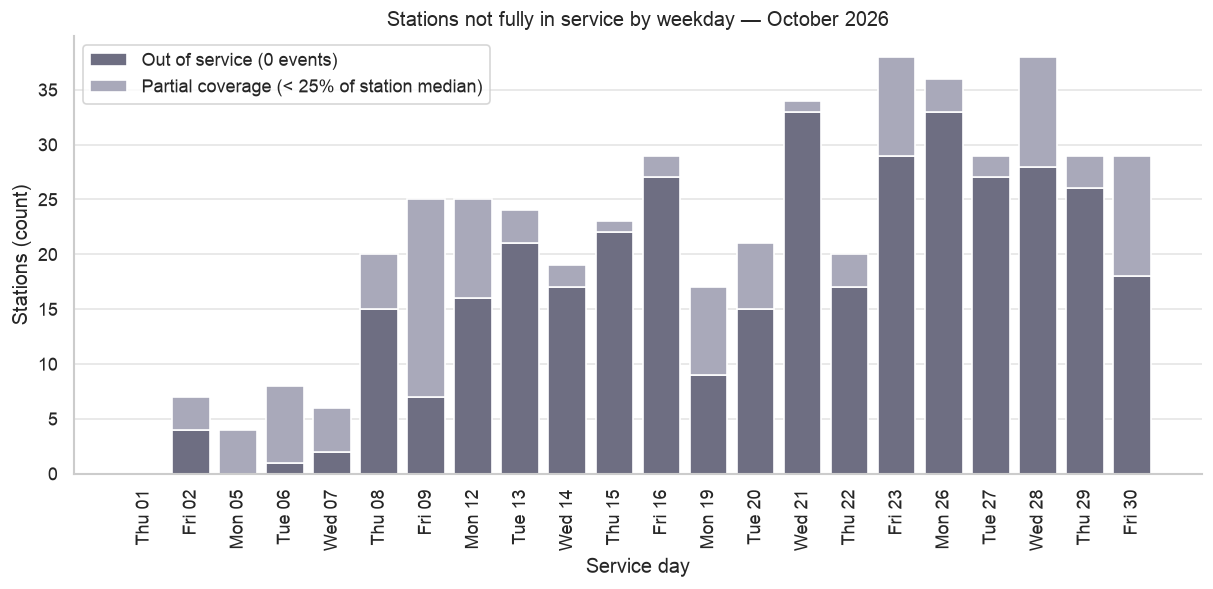

In [5]:
not_in_service = (
    coverage_2026.loc[coverage_2026["status"].ne("In service")]
    .groupby(["service_date", "status"]).size().unstack(fill_value=0)
    .reindex(index=weekday_service_dates(2026), columns=STATUS_ORDER[1:], fill_value=0)
)

# Look for dates when many stations were unavailable at once (zone closures) versus isolated outages.
fig, ax = plt.subplots(layout="constrained")
labels = not_in_service.index.strftime("%a %d")
ax.bar(labels, not_in_service["Out of service"], color=CONTEXT_EDGE, label="Out of service (0 events)")
ax.bar(labels, not_in_service["Partial coverage"], bottom=not_in_service["Out of service"],
       color=CONTEXT, label=f"Partial coverage (< {PARTIAL_THRESHOLD:.0%} of station median)")
ax.set(title="Stations not fully in service by weekday — October 2026",
       xlabel="Service day", ylabel="Stations (count)")
ax.tick_params(axis="x", labelrotation=90)
ax.legend()
plt.show()

In [6]:
station_coverage = (
    coverage_2026.groupby(["station", "status"]).size().unstack(fill_value=0)
    .reindex(columns=STATUS_ORDER, fill_value=0)
    .rename(columns=lambda status: f"{status} days")
)
first_excluded = (coverage_2026.loc[coverage_2026["status"].ne("In service")]
                  .groupby("station")["service_date"].agg(["min", "max"]))
station_coverage = station_coverage.join(first_excluded.rename(columns={"min": "first excluded day", "max": "last excluded day"}))

print("Stations by number of in-service weekdays (of 22):")
display(station_coverage["In service days"].value_counts().sort_index(ascending=False).rename("stations").to_frame().T)
print("Stations by number of out-of-service weekdays:")
display(station_coverage["Out of service days"].value_counts().sort_index().rename("stations").to_frame().T)
print("Stations with the fewest in-service days:")
station_coverage.sort_values("In service days").head(12)

Stations by number of in-service weekdays (of 22):


In service days,22,21,20,19,18,17,16,15
stations,410,136,80,32,10,3,1,4


Stations by number of out-of-service weekdays:


Out of service days,0,1,2,3,4,5,7
stations,451,131,70,14,4,2,4


Stations with the fewest in-service days:


,In service days,Partial coverage days,Out of service days,first excluded day,last excluded day
station,,,,,
136,15,0,7,2026-10-22,2026-10-30
137,15,0,7,2026-10-22,2026-10-30
135,15,0,7,2026-10-22,2026-10-30
134,15,0,7,2026-10-22,2026-10-30
152,16,2,4,2026-10-06,2026-10-14
140,17,2,3,2026-10-08,2026-10-14
117,17,0,5,2026-10-08,2026-10-14
397,17,0,5,2026-10-16,2026-10-29
155,18,0,4,2026-10-21,2026-10-28


### Coverage findings

- Of 14,872 station-days in October 2026 (676 stations × 22 weekdays), 14,391 (96.8%) are in service, 114 (0.8%) have partial coverage and 367 (2.5%) are out of service. October 2025 has only 26 out-of-service and 4 partial-coverage station-days, so outages are much more frequent in 2026.
- The threshold separates two clearly different groups: on in-service days, 95% of station-days reach at least 75% of the station's median (p5 = 0.75), while partial-coverage days have a median of 11 events. The 1,843 events on partial-coverage days are 0.07% of all clean events.
- Outages grow during the month: at most 8 stations per day are not fully in service from October 1 to 7, and between 17 and 38 per day from October 8 onward. 225 stations have at least one out-of-service day, mostly one or two days, which suggests rotating maintenance rather than permanent closures.
- 410 stations are in service on all 22 weekdays and every station on at least 15. The longest outage affects the four Álvaro Obregón stations (134–137), with no events from October 22 to 30.
- Reading out-of-service days as zero demand would lower the mean of these stations and bias their balance. All later statistics use in-service station-days only.

## 2. Hourly profile of the clean data and time slots

The profile uses the in-service station-days only and orders hours by **service day**, from 05:00 to 04:59. Counts are network averages per weekday service day. The hour 00:00–01:00 has only 30 minutes for pickups (the system closes at 00:30), and drop-offs after closing are kept, so the last slot extends to 04:59 for drop-offs.

Five slots summarize the day:

| Slot | Hours | Hours open for pickups | Role |
|---|---|---:|---|
| Early | 05:00–07:00 | 2 | Opening, low activity |
| AM peak | 07:00–10:00 | 3 | Morning commute |
| Midday | 10:00–16:00 | 6 | Intermediate activity, including the lunch increase |
| PM peak | 16:00–20:00 | 4 | Afternoon/evening commute |
| Evening | 20:00–00:30 (drop-offs to 04:59) | 4.5 | Decline until closing; late drop-offs |

Slots have different lengths. Totals per slot answer "how many bicycles leave or arrive in that part of the day", which is what matters for rebalancing; hourly rates (total ÷ hours) make slots comparable when needed.

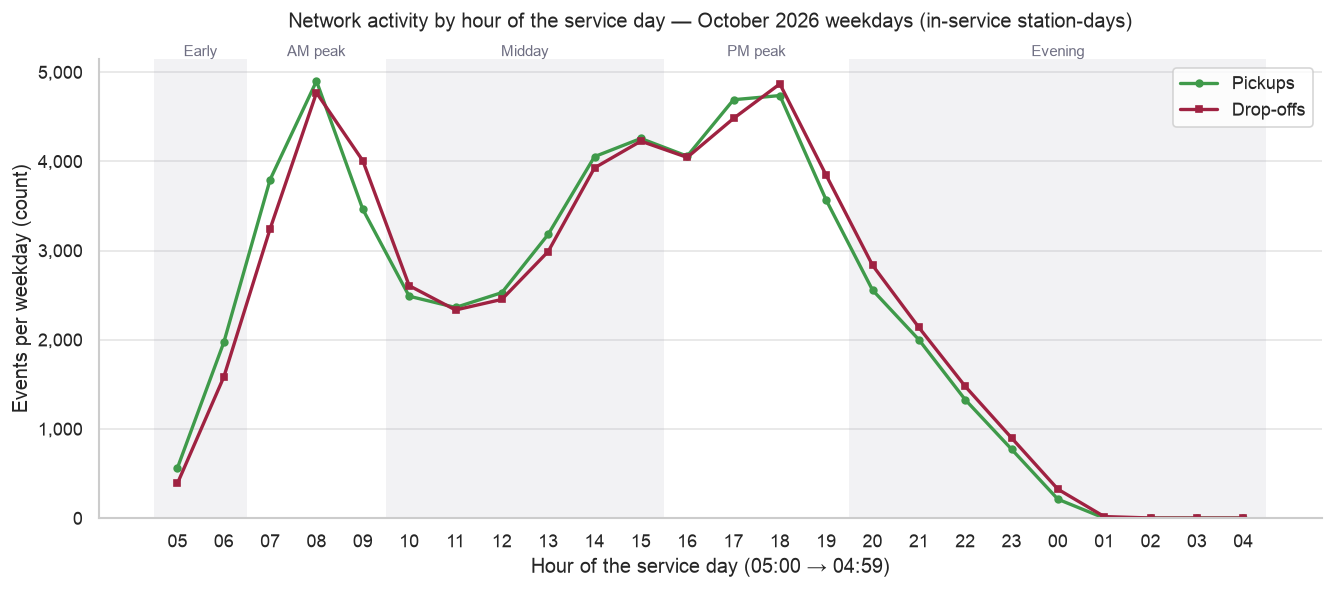

In [7]:
SERVICE_HOURS = list(range(5, 24)) + list(range(0, 5))  # service-day order: 05:00 ... 04:00
SLOT_HOURS = {
    "Early": range(5, 7),
    "AM peak": range(7, 10),
    "Midday": range(10, 16),
    "PM peak": range(16, 20),
    "Evening": [20, 21, 22, 23, 0, 1, 2, 3, 4],
}
SLOTS = list(SLOT_HOURS)
SLOT_OPEN_HOURS = pd.Series({"Early": 2, "AM peak": 3, "Midday": 6, "PM peak": 4, "Evening": 4.5})
HOUR_TO_SLOT = {hour: slot for slot, hours in SLOT_HOURS.items() for hour in hours}
SLOT_LABELS = {"Early": "Early\n05–07", "AM peak": "AM peak\n07–10", "Midday": "Midday\n10–16",
               "PM peak": "PM peak\n16–20", "Evening": "Evening\n20–00:30"}


def hourly_station_counts(clean, coverage):
    """Pickups and drop-offs per in-service station-day and hour; hours without events are zero."""
    in_service = coverage.loc[coverage["status"].eq("In service"), ["station", "service_date"]]
    grid = pd.MultiIndex.from_frame(in_service.merge(pd.DataFrame({"hour": range(24)}), how="cross"))
    counts = pd.concat({
        event: clean[event].assign(hour=clean[event]["hour"].astype("int64"))
                           .groupby(["station", "service_date", "hour"]).size()
        for event in EVENTS
    }, axis=1)
    # Reindexing to the in-service grid drops events of excluded station-days.
    counts = counts.reindex(grid, fill_value=0).fillna(0).astype("int64")
    counts["net"] = counts["dropoff"] - counts["pickup"]
    counts = counts.reset_index()
    counts["slot"] = pd.Categorical(counts["hour"].map(HOUR_TO_SLOT), categories=SLOTS, ordered=True)
    counts["service_hour"] = counts["hour"].map({hour: i for i, hour in enumerate(SERVICE_HOURS)})
    return counts


hourly_2026 = hourly_station_counts(clean_2026, coverage_2026)
hourly_2025 = hourly_station_counts(clean_2025, coverage_2025)

days_2026 = len(weekday_service_dates(2026))
network_hourly = (hourly_2026.groupby("hour")[EVENTS].sum() / days_2026).reindex(SERVICE_HOURS)

fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
x = np.arange(24)
# Shade alternate slots so their boundaries are visible behind the lines.
for i, slot in enumerate(SLOTS):
    hours = [SERVICE_HOURS.index(hour) for hour in SLOT_HOURS[slot]]
    if i % 2 == 0:
        ax.axvspan(min(hours) - 0.5, max(hours) + 0.5, color=CONTEXT, alpha=0.15, lw=0)
    ax.text((min(hours) + max(hours)) / 2, 1.0, slot, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9, color=CONTEXT_EDGE)
ax.plot(x, network_hourly["pickup"], color=PICKUP, marker="o", markersize=4, lw=2, label="Pickups")
ax.plot(x, network_hourly["dropoff"], color=DROPOFF, marker="s", markersize=4, lw=2, label="Drop-offs")
ax.set_xticks(x, [f"{hour:02d}" for hour in SERVICE_HOURS])
ax.set(title="Network activity by hour of the service day — October 2026 weekdays (in-service station-days)\n",
       xlabel="Hour of the service day (05:00 → 04:59)", ylabel="Events per weekday (count)", ylim=(0, None))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper right")
plt.show()

In [8]:
slot_totals = hourly_2026.groupby("slot", observed=True)[EVENTS].sum() / days_2026
slot_table = pd.DataFrame({
    "Hours open for pickups": SLOT_OPEN_HOURS,
    "Pickups per weekday": slot_totals["pickup"],
    "Drop-offs per weekday": slot_totals["dropoff"],
    "Share of daily pickups (%)": slot_totals["pickup"] / slot_totals["pickup"].sum() * 100,
    "Pickups per open hour": slot_totals["pickup"] / SLOT_OPEN_HOURS,
}).rename_axis("Slot")
peak_hours = network_hourly.idxmax()
print(f"Busiest hour for pickups: {peak_hours['pickup']:02d}:00; for drop-offs: {peak_hours['dropoff']:02d}:00")
slot_table.round(1)

Busiest hour for pickups: 08:00; for drop-offs: 18:00


,Hours open for pickups,Pickups per weekday,Drop-offs per weekday,Share of daily pickups (%),Pickups per open hour
Slot,,,,,
Early,2.0,2534.3,1972.6,4.4,1267.2
AM peak,3.0,12156.5,12019.2,21.2,4052.2
Midday,6.0,18866.1,18532.0,32.8,3144.3
PM peak,4.0,17050.9,17235.8,29.7,4262.7
Evening,4.5,6868.0,7692.3,11.9,1526.2


### Time-slot findings

- The clean weekday profile has two commute peaks: pickups are highest at 08:00–09:00 and drop-offs at 18:00–19:00. Activity is almost zero from 01:00 to 05:00, consistent with the service day.
- Per open hour, the AM peak (4,052 pickups) and PM peak (4,263) are the busiest slots. Midday averages 3,144 pickups per hour but is not uniform: it stays near 2,400–2,500 pickups per hour from 10:00 to 12:00 and rises to 4,000–4,250 from 14:00 to 16:00, so a Midday statistic mixes a quiet late morning with a busy early afternoon.
- The Midday slot carries the largest share of daily pickups (32.8%) because it is the longest; the AM and PM peaks carry 21.2% and 29.7% in fewer hours.
- Network totals of pickups and drop-offs are almost equal in every slot. Pickups lead drop-offs by about one hour within each peak (more pickups at 07:00, more drop-offs at 09:00), the typical trip duration. Imbalances are therefore a matter of **where** bicycles go, not of how many move in total.

## 3. Descriptive statistics by station and time slot

For each station, slot and event type, the statistics use the in-service days of that station only (between 15 and 22 weekdays). Days without events in a slot count as zero.

- **Mean, median, p25–p75 and standard deviation** of the daily count in the slot.
- **Dispersion index** = variance ÷ mean of the daily counts. A Poisson count with a constant rate has an index of 1; values above 1 indicate more day-to-day variation than that. It is reported here only as a description: whether a Poisson model fits, and at what time resolution, is a Stage 2 question.

The table `station_slot_stats` keeps every station; the display below shows the network summary and the most active stations.

In [9]:
def slot_counts(hourly):
    """Daily pickups, drop-offs and net flow per station and slot (in-service days only)."""
    by_slot = (hourly.groupby(["station", "service_date", "slot"], observed=True)[["pickup", "dropoff", "net"]]
               .sum().reset_index())
    whole_day = (hourly.groupby(["station", "service_date"])[["pickup", "dropoff", "net"]].sum()
                 .reset_index().assign(slot="Whole day"))
    table = pd.concat([by_slot, whole_day], ignore_index=True)
    table["slot"] = pd.Categorical(table["slot"], categories=SLOTS + ["Whole day"], ordered=True)
    return table


def describe_daily(values):
    return pd.Series({
        "days": values.size,
        "mean": values.mean(),
        "std": values.std(),
        "p25": values.quantile(0.25),
        "median": values.median(),
        "p75": values.quantile(0.75),
        "dispersion_index": values.var() / values.mean() if values.mean() > 0 else np.nan,
    })


slots_2026 = slot_counts(hourly_2026)
slots_2025 = slot_counts(hourly_2025)

station_slot_stats = (
    slots_2026.melt(id_vars=["station", "service_date", "slot"], value_vars=EVENTS,
                    var_name="event", value_name="count")
    .groupby(["station", "slot", "event"], observed=True)["count"].apply(describe_daily)
    .unstack()
)
station_slot_stats["days"] = station_slot_stats["days"].astype("int64")
print(f"station_slot_stats: {station_slot_stats.index.get_level_values('station').nunique()} stations × "
      f"{len(SLOTS) + 1} slots (including the whole day) × 2 events = {len(station_slot_stats):,} rows")
station_slot_stats.loc["271-272"].round(2)

station_slot_stats: 676 stations × 6 slots (including the whole day) × 2 events = 8,112 rows


days    mean     std     p25  median     p75  \
slot      event                                                   
Early     dropoff    22    9.27    2.83    7.25     9.0   10.75   
          pickup     22   66.09    7.80   61.75    68.5   72.00   
AM peak   dropoff    22   13.09    3.46   11.00    13.0   15.75   
          pickup     22  137.73   91.99   72.25    87.5  219.50   
Midday    dropoff    22  130.27   22.00  115.50   122.5  145.50   
          pickup     22   96.09   25.43   75.25    92.0  113.50   
PM peak   dropoff    22  514.68  120.98  422.75   532.5  598.50   
          pickup     22   62.50   16.29   50.00    62.0   72.50   
Evening   dropoff    22  149.91   46.66  113.25   151.5  164.50   
          pickup     22   35.50    9.03   30.00    35.5   40.50   
Whole day dropoff    22  817.23  148.85  703.25   810.5  904.50   
          pickup     22  397.91  108.30  325.00   344.5  485.75   

                   dispersion_index  
slot      event                      
Early     dropoff              0.86  
          pickup               0.92  
AM peak   dropoff              0.92  
          pickup              61.44  
Midday    dropoff              3.72  
          pickup               6.73  
PM peak   dropoff             28.44  
          pickup               4.25  
Evening   dropoff             14.52  
          pickup               2.30  
Whole day dropoff             27.11  
          pickup              29.48

In [10]:
# Network view: how much does a typical station move in each slot, and how variable is it?
network_slot_summary = (
    station_slot_stats.reset_index()
    .groupby(["slot", "event"], observed=True)
    .agg(**{
        "Stations": ("mean", "size"),
        "Median of station means": ("mean", "median"),
        "p90 of station means": ("mean", lambda s: s.quantile(0.9)),
        "Median dispersion index": ("dispersion_index", "median"),
        "Stations with dispersion index > 2 (%)": ("dispersion_index", lambda s: s.gt(2).mean() * 100),
    })
)
network_slot_summary.round(2)

Stations  Median of station means  p90 of station means  \
slot      event                                                              
Early     dropoff       676                     1.92                  6.93   
          pickup        676                     2.86                  7.32   
AM peak   dropoff       676                    14.20                 37.11   
          pickup        676                    15.72                 31.43   
Midday    dropoff       676                    23.05                 54.12   
          pickup        676                    24.77                 52.80   
PM peak   dropoff       676                    20.86                 47.32   
          pickup        676                    21.64                 50.25   
Evening   dropoff       676                    10.36                 20.86   
          pickup        676                     8.32                 21.07   
Whole day dropoff       676                    73.91                159.20   
          pickup        676                    75.47                156.07   

                   Median dispersion index  \
slot      event                              
Early     dropoff                     0.81   
          pickup                      0.90   
AM peak   dropoff                     1.08   
          pickup                      1.53   
Midday    dropoff                     1.35   
          pickup                      1.50   
PM peak   dropoff                     1.77   
          pickup                      2.14   
Evening   dropoff                     1.69   
          pickup                      1.67   
Whole day dropoff                     2.03   
          pickup                      2.27   

                   Stations with dispersion index > 2 (%)  
slot      event                                            
Early     dropoff                                    2.22  
          pickup                                     3.25  
AM peak   dropoff                                   18.05  
          pickup                                    31.66  
Midday    dropoff                                   25.44  
          pickup                                    27.96  
PM peak   dropoff                                   40.38  
          pickup                                    54.59  
Evening   dropoff                                   36.54  
          pickup                                    35.95  
Whole day dropoff                                   51.18  
          pickup                                    56.95

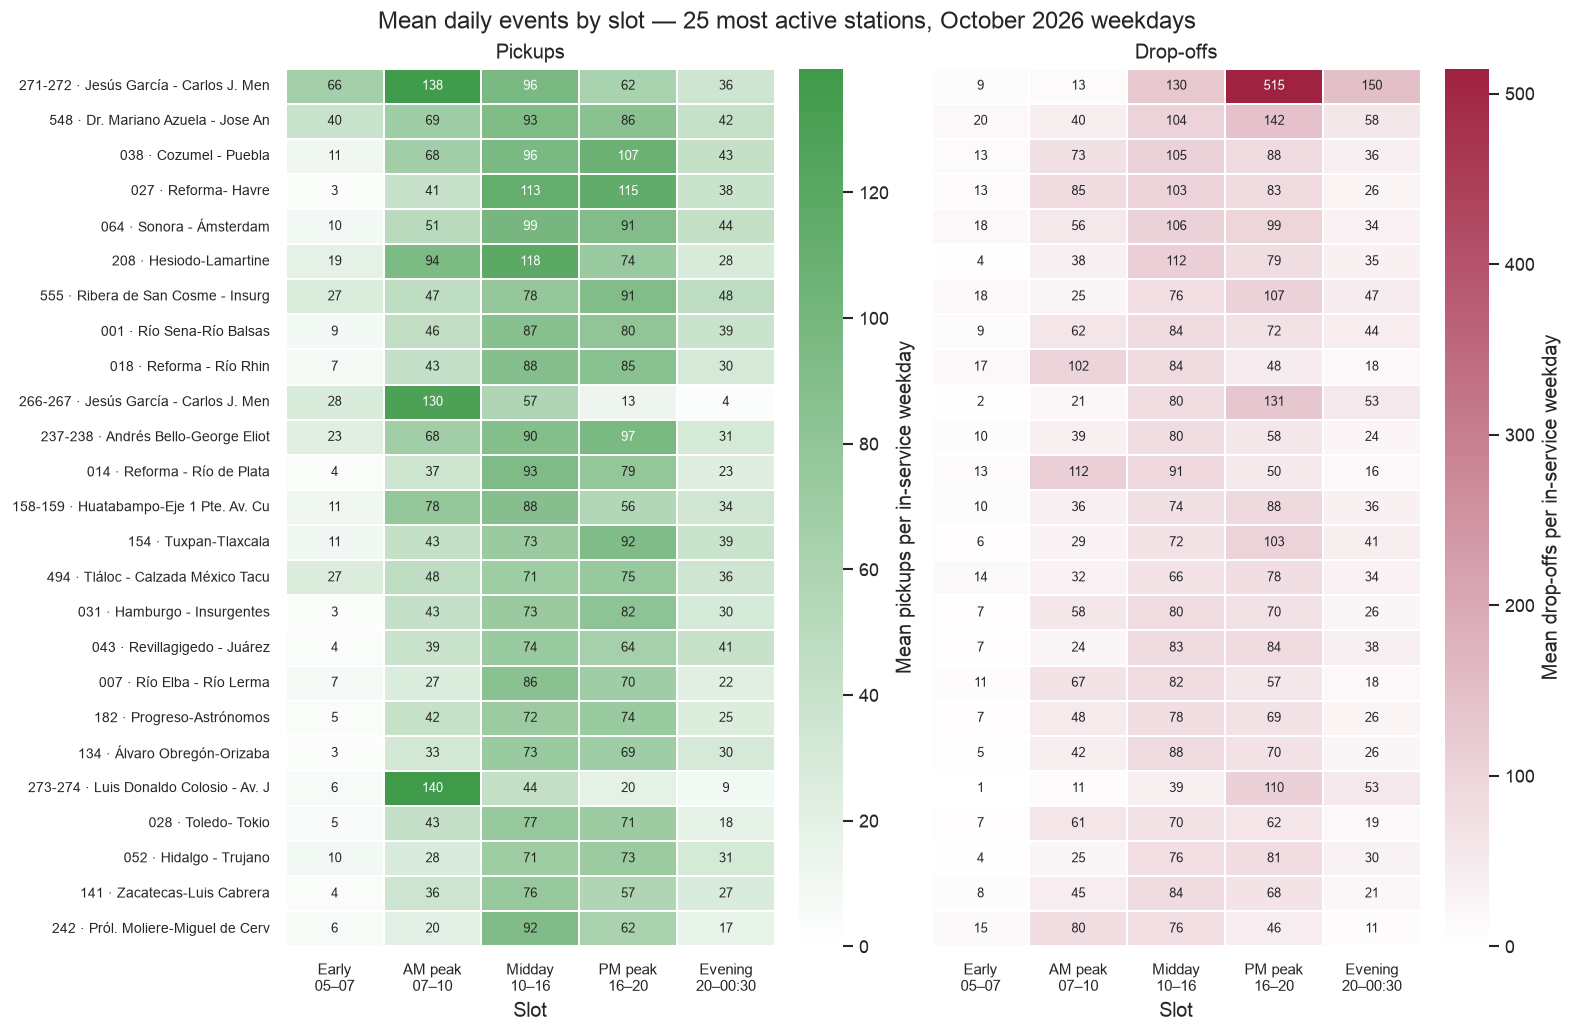

In [11]:
TOP_STATIONS = 25
station_activity = slots_2026.loc[slots_2026["slot"].eq("Whole day")].groupby("station")[EVENTS].mean()
top_stations = (station_activity.sum(axis=1).sort_values(ascending=False).head(TOP_STATIONS).index)
station_names = station_catalog.set_index("short_name")["name"]


def station_label(code):
    name = station_names.get(code, "")
    name = name.split(" ", 1)[1] if name.startswith("CE-") else name  # drop the repeated "CE-<code>" prefix
    return f"{code} · {name[:28]}"


slot_means = station_slot_stats["mean"].unstack(["event", "slot"])
# Compare when the busiest stations release bicycles (pickups) and when they receive them (drop-offs).
fig, axes = plt.subplots(1, 2, figsize=(13, 8.5), sharey=True, layout="constrained")
for ax, event, cmap, title in [(axes[0], "pickup", PICKUP_CMAP, "Pickups"), (axes[1], "dropoff", DROPOFF_CMAP, "Drop-offs")]:
    data = slot_means[event].loc[top_stations, SLOTS]
    sns.heatmap(data, cmap=cmap, vmin=0, annot=True, fmt=".0f", annot_kws={"fontsize": 8},
                linewidths=1, linecolor="white", ax=ax,
                cbar_kws={"label": f"Mean {title.lower()} per in-service weekday"})
    ax.set(title=title, xlabel="Slot", ylabel="")
    ax.set_xticklabels([SLOT_LABELS[slot] for slot in SLOTS], rotation=0, fontsize=9)
    ax.grid(False)
axes[0].set_yticklabels([station_label(code) for code in top_stations], fontsize=8.5)
fig.suptitle(f"Mean daily events by slot — {TOP_STATIONS} most active stations, October 2026 weekdays")
plt.show()

### Descriptive findings

- The median station records about 75 pickups and 74 drop-offs per in-service weekday; the 90th percentile is about 156–159. Activity is highly concentrated: `271-272` (Jesús García – Carlos J. Meneses) averages 398 pickups and 817 drop-offs per day, 515 of the drop-offs in the PM peak.
- The busiest stations differ in **when** they are used. Stations `271-272`, `266-267` and `273-274` on Jesús García / Luis Donaldo Colosio release 130–140 bicycles in the AM peak and receive their largest number of drop-offs in the PM peak; Reforma stations such as `014` and `018` show the opposite pattern (for example, `014` receives 112 bicycles and releases 37 in the AM peak).
- The dispersion index grows with the length of the slot. Early-slot counts have a median index of 0.8–0.9, close to a Poisson count with a constant rate. In the AM peak the median is 1.1 for drop-offs and 1.5 for pickups, and over the whole day it is 2.0–2.3, with more than half of the stations above 2.
- Daily counts in long slots therefore vary more from day to day than a constant-rate Poisson count would. Possible reasons include a rate that changes within the slot, day-to-day effects such as weather or events, and censoring at empty or full stations. Stage 2 should choose the time resolution of its rates with this in mind.

## 4. Recurrent imbalances

**Net flow = drop-offs − pickups** for a station in a slot of one service day. A negative value means more bicycles left than arrived (*net outflow*: the station empties); a positive value means more arrived than left (*net inflow*: the station fills). This describes movements recorded in completed trips. It is not the station inventory: the operator's rebalancing trucks are not in the files, and a station that is already empty or full cannot record the trips it denies.

### 4.1 Criterion for a systematic imbalance

A station–slot is called **systematically imbalanced** when all three conditions hold:

| Condition | Threshold | Reason |
|---|---|---|
| Coverage | At least 15 in-service weekdays | Two-thirds of the month; every station meets it in 2026 |
| Recurrence | The same sign on at least 80% of in-service days | The imbalance repeats on most days, not only on average. Days with zero net count against the share. |
| Magnitude | \|median net flow\| ≥ 10% of the published capacity | Small but consistent imbalances do not require intervention; the threshold is relative to the size of the station. |

As supporting evidence, a two-sided **sign test** checks whether positive and negative days are equally likely. With 22 days, 18 days of the same sign give p ≈ 0.004. Because the test is repeated over about 4,000 station–slots, the p-values are reported for reference and the decision rests on the fixed criterion above. Capacities come from the November 19, 2026 catalog.

In [12]:
MIN_DAYS = 15
RECURRENCE = 0.80
MAGNITUDE = 0.10  # share of published capacity


def sign_test_p(positive, negative):
    """Two-sided exact sign test; days with zero net flow are left out."""
    n = positive + negative
    if n == 0:
        return np.nan
    k = max(positive, negative)
    tail = sum(comb(n, i) for i in range(k, n + 1)) / 2 ** n
    return min(1.0, 2 * tail)


def net_flow_stats(slots, catalog):
    """Net-flow statistics and the systematic-imbalance flag for each station and slot."""
    grouped = slots.groupby(["station", "slot"], observed=True)["net"]
    stats = grouped.agg(days="size", mean_net="mean", median_net="median",
                        p25_net=lambda s: s.quantile(0.25), p75_net=lambda s: s.quantile(0.75),
                        negative_days=lambda s: int(s.lt(0).sum()), positive_days=lambda s: int(s.gt(0).sum()))
    stats["share_negative"] = stats["negative_days"] / stats["days"]
    stats["share_positive"] = stats["positive_days"] / stats["days"]
    stats["sign_test_p"] = [sign_test_p(pos, neg) for pos, neg in zip(stats["positive_days"], stats["negative_days"])]
    stats = stats.join(catalog.set_index("short_name")["capacity"], on="station")
    stats["median_net_to_capacity"] = stats["median_net"] / stats["capacity"]

    outflow = stats["share_negative"].ge(RECURRENCE) & stats["median_net_to_capacity"].le(-MAGNITUDE)
    inflow = stats["share_positive"].ge(RECURRENCE) & stats["median_net_to_capacity"].ge(MAGNITUDE)
    stats["imbalance"] = np.select(
        [stats["days"].lt(MIN_DAYS) | stats["capacity"].isna(), outflow, inflow],
        ["Insufficient data", "Systematic outflow", "Systematic inflow"], "Not systematic",
    )
    return stats


net_stats_2026 = net_flow_stats(slots_2026, station_catalog)
net_stats_2025 = net_flow_stats(slots_2025, station_catalog)

IMBALANCE_ORDER = ["Systematic outflow", "Systematic inflow", "Not systematic", "Insufficient data"]
imbalance_counts = (net_stats_2026.groupby(["slot", "imbalance"], observed=True).size()
                    .unstack(fill_value=0).reindex(columns=IMBALANCE_ORDER, fill_value=0))
imbalance_counts["Systematic (% of stations)"] = (
    imbalance_counts[IMBALANCE_ORDER[:2]].sum(axis=1) / imbalance_counts[IMBALANCE_ORDER].sum(axis=1) * 100)
imbalance_counts.round(1)

imbalance,Systematic outflow,Systematic inflow,Not systematic,Insufficient data,Systematic (% of stations)
slot,,,,,
Early,158,65,453,0,33.0
AM peak,261,193,222,0,67.2
Midday,80,53,543,0,19.7
PM peak,162,158,356,0,47.3
Evening,64,166,446,0,34.0
Whole day,129,98,449,0,33.6


In [13]:
# How sensitive is the number of flagged station-slots to the two thresholds?
sensitivity_rows = []
for recurrence in [0.70, 0.80, 0.90]:
    for magnitude in [0.05, 0.10, 0.20]:
        flagged = (
            (net_stats_2026["share_negative"].ge(recurrence) & net_stats_2026["median_net_to_capacity"].le(-magnitude))
            | (net_stats_2026["share_positive"].ge(recurrence) & net_stats_2026["median_net_to_capacity"].ge(magnitude))
        ) & net_stats_2026["days"].ge(MIN_DAYS)
        flagged_slots = flagged.loc[(slice(None), SLOTS)]
        sensitivity_rows.append({
            "Recurrence (same sign, share of days)": f"{recurrence:.0%}",
            "Magnitude (|median| / capacity)": f"{magnitude:.0%}",
            "Station-slots flagged (5 slots)": int(flagged_slots.sum()),
            "Stations with ≥ 1 flagged slot": flagged_slots.groupby(level="station").any().sum(),
        })
threshold_sensitivity = pd.DataFrame(sensitivity_rows).set_index(
    ["Recurrence (same sign, share of days)", "Magnitude (|median| / capacity)"])
threshold_sensitivity

Station-slots flagged (5 slots)  \
Recurrence (same sign, share of days) Magnitude (|median| / capacity)                                    
70%                                   5%                                                          1873   
                                      10%                                                         1621   
                                      20%                                                         1082   
80%                                   5%                                                          1482   
                                      10%                                                         1360   
                                      20%                                                         1010   
90%                                   5%                                                          1055   
                                      10%                                                         1007   
                                      20%                                                          835   

                                                                       Stations with ≥ 1 flagged slot  
Recurrence (same sign, share of days) Magnitude (|median| / capacity)                                  
70%                                   5%                                                          636  
                                      10%                                                         598  
                                      20%                                                         479  
80%                                   5%                                                          579  
                                      10%                                                         557  
                                      20%                                                         462  
90%                                   5%                                                          492  
                                      10%                                                         477  
                                      20%                                                         426

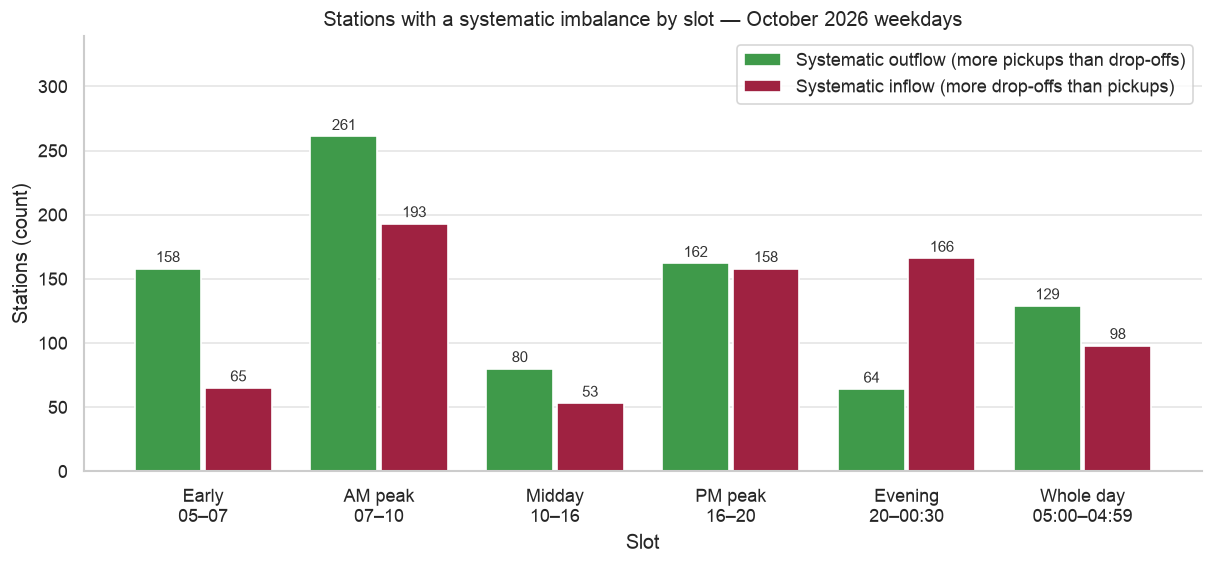

In [14]:
# Where in the day do systematic imbalances occur, and in which direction?
plot_counts = imbalance_counts.loc[SLOTS + ["Whole day"], IMBALANCE_ORDER[:2]]
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
x = np.arange(len(plot_counts))
width = 0.38
bars_out = ax.bar(x - width / 2 - 0.01, plot_counts["Systematic outflow"], width, color=PICKUP,
                  label="Systematic outflow (more pickups than drop-offs)")
bars_in = ax.bar(x + width / 2 + 0.01, plot_counts["Systematic inflow"], width, color=DROPOFF,
                 label="Systematic inflow (more drop-offs than pickups)")
for bars in [bars_out, bars_in]:
    ax.bar_label(bars, fontsize=9, padding=2, color=INK)
ax.set_xticks(x, [SLOT_LABELS.get(slot, "Whole day\n05:00–04:59") for slot in plot_counts.index])
ax.set(title="Stations with a systematic imbalance by slot — October 2026 weekdays",
       ylabel="Stations (count)", xlabel="Slot", ylim=(0, plot_counts.to_numpy().max() * 1.3))
ax.legend(loc="upper right")
plt.show()

### 4.2 Intraday cumulative net flow

A whole-day net flow close to zero can hide a station that empties in the morning and fills again in the evening. Starting from zero at 05:00, the cumulative net flow is added hour by hour for each in-service day. Three quantities summarize each station-day:

- **Maximum deficit:** the largest number of bicycles the station is behind its 05:00 level (how many bicycles it needs at opening to avoid running out).
- **Maximum surplus:** the largest number of bicycles it is ahead (how many free docks it needs).
- **Swing** = maximum surplus + maximum deficit: the range the station moves through in one day.

Each station is described by the median of these values across its in-service days and compared with its published capacity. A swing above the capacity means that, without rebalancing, no starting inventory can absorb that day's movements: the station must have emptied or filled at some point, or the operator intervened.

In [15]:
def intraday_profile(hourly):
    """Cumulative net flow from 05:00 for each in-service station-day."""
    ordered = hourly.sort_values(["station", "service_date", "service_hour"])
    cumulative = ordered.groupby(["station", "service_date"])["net"].cumsum()
    by_day = ordered.assign(cumulative=cumulative).groupby(["station", "service_date"])["cumulative"]
    days = pd.DataFrame({
        "max_deficit": (-by_day.min()).clip(lower=0),
        "max_surplus": by_day.max().clip(lower=0),
        "end_of_day_net": by_day.last(),
    })
    days["swing"] = days["max_deficit"] + days["max_surplus"]
    return days


def intraday_summary(hourly, catalog):
    days = intraday_profile(hourly)
    summary = days.groupby("station").median().add_prefix("median_")
    summary = summary.join(catalog.set_index("short_name")["capacity"])
    summary["swing_to_capacity"] = summary["median_swing"] / summary["capacity"]
    summary["deficit_to_capacity"] = summary["median_max_deficit"] / summary["capacity"]
    summary["surplus_to_capacity"] = summary["median_max_surplus"] / summary["capacity"]
    return summary


intraday_2026 = intraday_summary(hourly_2026, station_catalog)
whole_day_net = net_stats_2026.xs("Whole day", level="slot")
hidden = (intraday_2026["swing_to_capacity"].ge(0.5)
          & whole_day_net["median_net_to_capacity"].abs().lt(MAGNITUDE))

pd.Series({
    "Stations": len(intraday_2026),
    "Median swing (bicycles)": intraday_2026["median_swing"].median(),
    "Median swing / capacity": intraday_2026["swing_to_capacity"].median(),
    "Stations with median swing ≥ 50% of capacity": int(intraday_2026["swing_to_capacity"].ge(0.5).sum()),
    "Stations with median swing ≥ 100% of capacity": int(intraday_2026["swing_to_capacity"].ge(1.0).sum()),
    "…of the ≥ 50% group, whole-day |median net| < 10% of capacity": int(hidden.sum()),
}, name="October 2026").round(2).to_frame()

,October 2026
Stations,676.0
Median swing (bicycles),18.0
Median swing / capacity,0.7
Stations with median swing ≥ 50% of capacity,483.0
Stations with median swing ≥ 100% of capacity,177.0
"…of the ≥ 50% group, whole-day |median net| < 10% of capacity",112.0


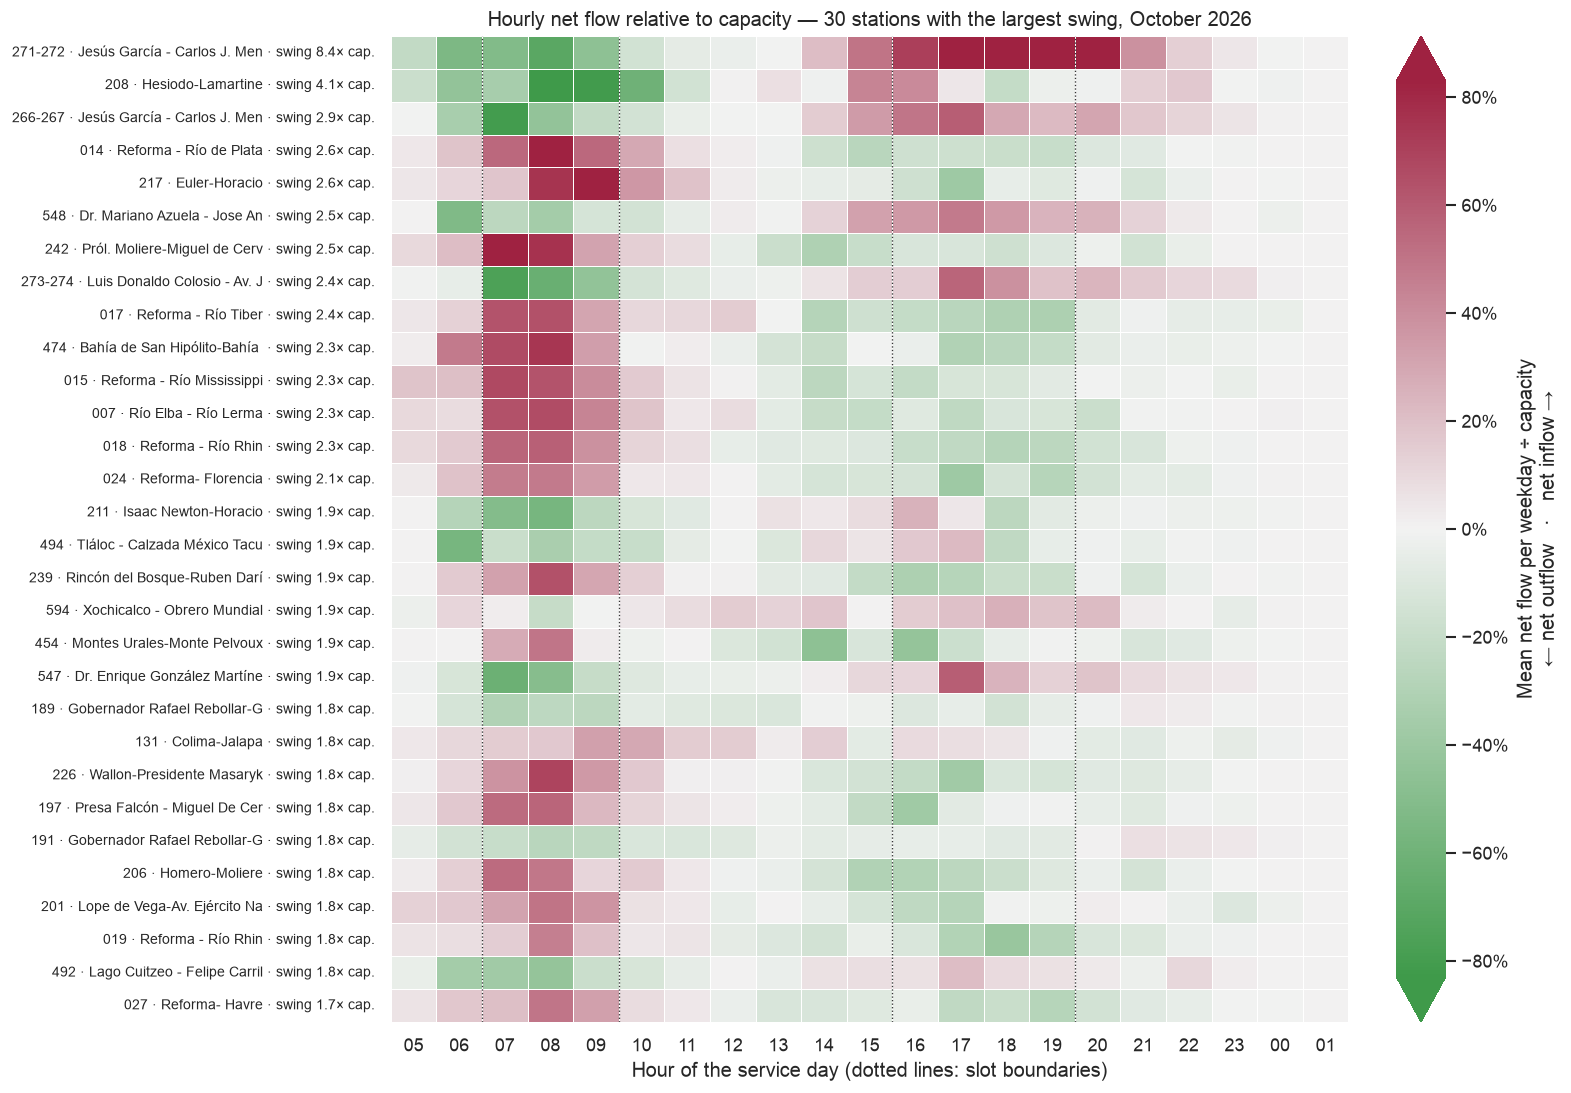

In [16]:
HEATMAP_STATIONS = 30
heatmap_stations = intraday_2026["swing_to_capacity"].sort_values(ascending=False).head(HEATMAP_STATIONS).index
hourly_mean_net = (hourly_2026.loc[hourly_2026["station"].isin(heatmap_stations)]
                   .groupby(["station", "hour"])["net"].mean().unstack()
                   .reindex(index=heatmap_stations, columns=SERVICE_HOURS[:21]))  # 05:00–01:59; later hours are ~0
# Express each row relative to the station's capacity so small and large stations share one scale.
hourly_net_to_capacity = hourly_mean_net.div(intraday_2026.loc[heatmap_stations, "capacity"], axis=0)
limit = np.nanquantile(np.abs(hourly_net_to_capacity.to_numpy()), 0.99)

# Read each row from left to right: green hours drain the station, maroon hours refill it.
fig, ax = plt.subplots(figsize=(13, 9), layout="constrained")
sns.heatmap(hourly_net_to_capacity, cmap=NET_CMAP, norm=TwoSlopeNorm(0, -limit, limit),
            linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Mean net flow per weekday ÷ capacity\n← net outflow   ·   net inflow →",
                      "extend": "both", "format": StrMethodFormatter("{x:.0%}")})
ax.set_xticklabels([f"{hour:02d}" for hour in SERVICE_HOURS[:21]], rotation=0)
ax.set_yticklabels([f"{station_label(code)} · swing {intraday_2026.loc[code, 'swing_to_capacity']:.1f}× cap."
                    for code in heatmap_stations], fontsize=8.5)
for boundary in [2, 5, 11, 15]:  # slot boundaries in service-hour positions
    ax.axvline(boundary, color=INK, lw=0.8, ls=":")
ax.set(title=f"Hourly net flow relative to capacity — {HEATMAP_STATIONS} stations with the largest swing, October 2026",
       xlabel="Hour of the service day (dotted lines: slot boundaries)", ylabel="")
ax.grid(False)
plt.show()

### 4.3 Station types and where they are

Combining the two commute slots gives a simple typology. It uses only the systematic flags of the AM and PM peaks and of the whole day, in this order of precedence:

| Type | Rule |
|---|---|
| Morning source, evening sink | Systematic outflow in the AM peak and systematic inflow in the PM peak |
| Morning sink, evening source | Systematic inflow in the AM peak and systematic outflow in the PM peak |
| Net source (whole day) | Systematic outflow over the whole day |
| Net sink (whole day) | Systematic inflow over the whole day |
| One-peak imbalance | A systematic flag in only one of the two peaks |
| Other systematic slot | A systematic flag only in the Early, Midday or Evening slot |
| No systematic imbalance | None of the above |

Complementary stations, for example a morning source next to a morning sink, are what a subnetwork can balance internally.

In [17]:
STATION_TYPES = ["Morning source, evening sink", "Morning sink, evening source", "Net source (whole day)",
                 "Net sink (whole day)", "One-peak imbalance", "Other systematic slot", "No systematic imbalance"]


def station_types(net_stats):
    flags = net_stats["imbalance"].unstack("slot")
    am, pm, day = flags["AM peak"], flags["PM peak"], flags["Whole day"]
    systematic = flags.isin(["Systematic outflow", "Systematic inflow"])
    conditions = [
        am.eq("Systematic outflow") & pm.eq("Systematic inflow"),
        am.eq("Systematic inflow") & pm.eq("Systematic outflow"),
        day.eq("Systematic outflow"),
        day.eq("Systematic inflow"),
        systematic["AM peak"] | systematic["PM peak"],
        systematic[["Early", "Midday", "Evening"]].any(axis=1),
    ]
    return pd.Series(np.select(conditions, STATION_TYPES[:-1], STATION_TYPES[-1]), index=flags.index, name="station_type")


station_type_2026 = station_types(net_stats_2026)
station_type_2026.value_counts().reindex(STATION_TYPES, fill_value=0).rename("Stations").to_frame()

,Stations
station_type,
"Morning source, evening sink",135
"Morning sink, evening source",133
Net source (whole day),94
Net sink (whole day),46
One-peak imbalance,121
Other systematic slot,45
No systematic imbalance,102


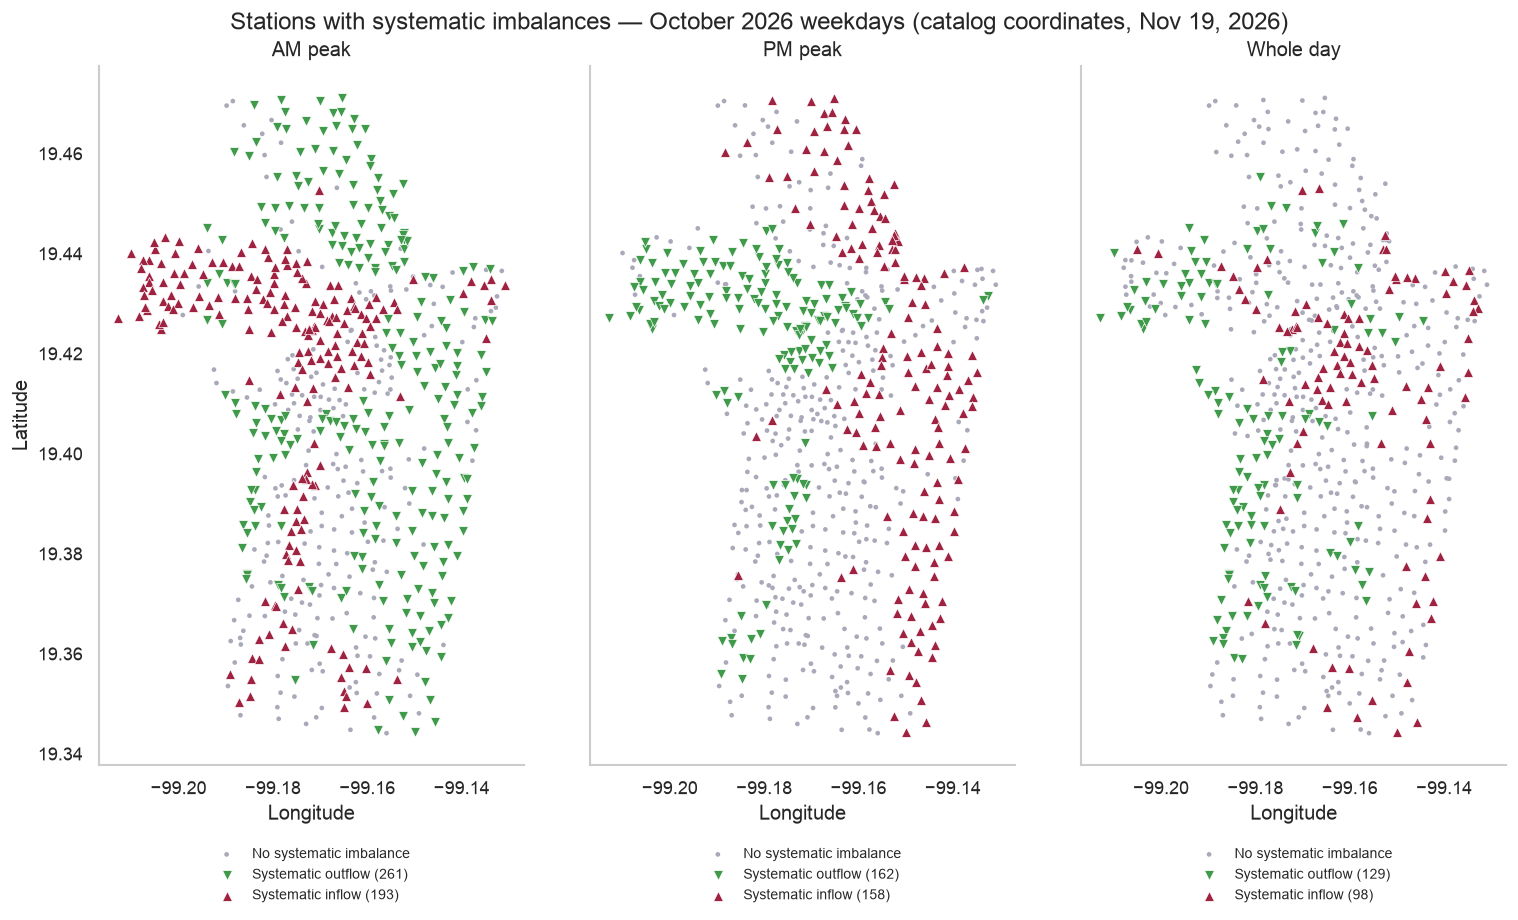

In [18]:
map_data = station_catalog.set_index("short_name")[["lat", "lon"]]
flags_2026 = net_stats_2026["imbalance"].unstack("slot")
DIRECTION_STYLE = {
    "Systematic outflow": dict(color=PICKUP, marker="v", s=34, label="Systematic outflow"),
    "Systematic inflow": dict(color=DROPOFF, marker="^", s=34, label="Systematic inflow"),
}

# Compare the two peaks: the same areas tend to switch direction between morning and evening.
fig, axes = plt.subplots(1, 3, figsize=(13, 7.6), sharex=True, sharey=True, layout="constrained")
for ax, slot in zip(axes, ["AM peak", "PM peak", "Whole day"]):
    located = flags_2026[[slot]].join(map_data, how="inner")
    background = located[~located[slot].isin(list(DIRECTION_STYLE))]
    ax.scatter(background["lon"], background["lat"], s=8, color=CONTEXT, edgecolor="none",
               label="No systematic imbalance")
    for flag, style in DIRECTION_STYLE.items():
        points = located[located[slot].eq(flag)]
        ax.scatter(points["lon"], points["lat"], edgecolor="white", linewidth=0.4,
                   **{**style, "label": f"{style['label']} ({len(points)})"})
    ax.set(title=slot, xlabel="Longitude")
    ax.set_aspect(1 / np.cos(np.radians(19.4)))  # equal distances in both directions at Mexico City's latitude
    ax.grid(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8.5, frameon=False)
axes[0].set_ylabel("Latitude")
fig.suptitle("Stations with systematic imbalances — October 2026 weekdays (catalog coordinates, Nov 19, 2026)")
plt.show()

### Imbalance findings

- **Systematic imbalances are common and concentrated in the commute peaks.** In the AM peak, 454 stations (67%) are systematically imbalanced: 261 with outflow and 193 with inflow. In the PM peak, 320 stations (47%) are, with 162 outflows and 158 inflows. Midday has the fewest flagged stations (133, 20%).
- The Early slot is dominated by outflow (158 stations) and the Evening slot by inflow (166 stations), the beginning and end of the commute pattern.
- **227 stations (34%) are also imbalanced over the whole day:** 129 net sources and 98 net sinks. For these stations the imbalance does not cancel within the day, so it must be corrected by rebalancing or it accumulates.
- **The criterion is not fragile.** With the baseline thresholds (80% of days, 10% of capacity), 1,360 station-slots are flagged in the five slots and 557 stations have at least one flagged slot. Across the nine combinations tested, these figures range from 835 to 1,873 and from 426 to 636. The size of the problem changes with the thresholds, but the conclusion that most stations have some systematic imbalance does not.
- **Intraday swings are large relative to capacity.** The median station moves through 18 bicycles in a day, 0.7 times its capacity. 483 stations have a median swing of at least half their capacity and 177 of at least their full capacity. Of the first group, 112 have a whole-day net flow below 10% of capacity: they look balanced at the end of the day but empty and refill within it.
- **Extreme cases:**
  - `271-272` has a median whole-day net inflow of 423 bicycles and a swing of 620, 8.4 times its 74 docks. It can only operate with continuous removal of bicycles.
  - `208` (Hesiodo – Lamartine) is a net source of about 70 bicycles per day with 25 docks.
- **Typology:** 135 morning-source/evening-sink stations, 133 morning-sink/evening-source stations, 94 whole-day net sources, 46 whole-day net sinks, 121 with an imbalance in only one peak, 45 with a flag only outside the peaks, and 102 without a systematic imbalance.
- **Geography:** in the AM peak, inflow concentrates in the west (the Polanco stations around Campos Elíseos, Homero and Moliere) and along the Reforma corridor, while outflow dominates in the north, east and south of the network. The PM peak reverses this pattern. Whole-day net sources concentrate in the west: in Polanco and in a north–south band around longitude −99.18 between latitudes 19.36 and 19.42. Whole-day net sinks lie mostly in the centre and east of the network. The causes of that whole-day pattern (terrain, transit connections, trip purpose) are not tested here.
- **Implication for the subnetwork:** within a few blocks there are stations of opposite types. A contiguous group that combines morning sources and morning sinks can partly balance itself through user trips, while a group made only of one type depends entirely on rebalancing.

## 5. Stability of the imbalances

A recurrent imbalance is useful for planning only if it persists. Two checks, both on the mean net flow per station and slot over in-service days:

1. **Within October 2026:** first half (October 1–16, 12 weekdays) versus second half (October 19–30, 10 weekdays). More stations were out of service in the second half (Section 1); each half uses only the in-service days of each station.
2. **October 2025 versus October 2026:** same rules and criterion in both years, for stations present in both files. Station identity is matched by code; locations and capacities come from the 2026 catalog. The drop-offs after midnight of Friday, October 31, 2025 are in the November file, which slightly lowers the Evening slot of that one day.

For each slot the table reports the correlation of station mean net flows between the two periods, the share of stations with the same sign, and how many of the 2026 systematic station-slots keep their direction.

In [19]:
HALF_SPLIT = pd.Timestamp("2026-10-17")
period_means = {
    "2026 first half": slots_2026.loc[slots_2026["service_date"].lt(HALF_SPLIT)],
    "2026 second half": slots_2026.loc[slots_2026["service_date"].ge(HALF_SPLIT)],
    "2025": slots_2025,
}
period_means = {name: table.groupby(["station", "slot"], observed=True)["net"].mean() for name, table in period_means.items()}
mean_net_2026 = net_stats_2026["mean_net"]
systematic_2026 = net_stats_2026["imbalance"].isin(["Systematic outflow", "Systematic inflow"])
direction_2026 = np.sign(net_stats_2026["median_net"])


def compare_periods(first, second, label):
    rows = []
    for slot in SLOTS + ["Whole day"]:
        pair = pd.concat({"first": first.xs(slot, level="slot"), "second": second.xs(slot, level="slot")}, axis=1).dropna()
        flagged = systematic_2026.xs(slot, level="slot")
        flagged = flagged[flagged].index.intersection(pair.index)
        direction = direction_2026.xs(slot, level="slot").loc[flagged]
        same_direction = (np.sign(pair.loc[flagged, "first"]).eq(direction)
                          & np.sign(pair.loc[flagged, "second"]).eq(direction))
        rows.append({
            "Comparison": label, "Slot": slot,
            "Stations compared": len(pair),
            "Correlation of mean net flow": pair["first"].corr(pair["second"]),
            "Same sign (% of stations)": np.sign(pair["first"]).eq(np.sign(pair["second"])).mean() * 100,
            "2026 systematic station-slots": len(flagged),
            "…same direction in both periods (%)": same_direction.mean() * 100 if len(flagged) else np.nan,
        })
    return rows


stability = pd.DataFrame(
    compare_periods(period_means["2026 first half"], period_means["2026 second half"], "2026: first vs second half")
    + compare_periods(period_means["2025"], mean_net_2026, "October 2025 vs October 2026")
).set_index(["Comparison", "Slot"])
stability.round(2)

Stations compared  \
Comparison                   Slot                           
2026: first vs second half   Early                    676   
                             AM peak                  676   
                             Midday                   676   
                             PM peak                  676   
                             Evening                  676   
                             Whole day                676   
October 2025 vs October 2026 Early                    676   
                             AM peak                  676   
                             Midday                   676   
                             PM peak                  676   
                             Evening                  676   
                             Whole day                676   

                                        Correlation of mean net flow  \
Comparison                   Slot                                      
2026: first vs second half   Early                              0.95   
                             AM peak                            0.93   
                             Midday                             0.87   
                             PM peak                            0.99   
                             Evening                            0.95   
                             Whole day                          0.94   
October 2025 vs October 2026 Early                              0.92   
                             AM peak                            0.91   
                             Midday                             0.77   
                             PM peak                            0.96   
                             Evening                            0.93   
                             Whole day                          0.89   

                                        Same sign (% of stations)  \
Comparison                   Slot                                   
2026: first vs second half   Early                          86.09   
                             AM peak                        93.34   
                             Midday                         79.29   
                             PM peak                        86.98   
                             Evening                        88.02   
                             Whole day                      84.62   
October 2025 vs October 2026 Early                          82.84   
                             AM peak                        91.57   
                             Midday                         70.56   
                             PM peak                        86.54   
                             Evening                        88.76   
                             Whole day                      76.78   

                                        2026 systematic station-slots  \
Comparison                   Slot                                       
2026: first vs second half   Early                                223   
                             AM peak                              454   
                             Midday                               133   
                             PM peak                              320   
                             Evening                              230   
                             Whole day                            227   
October 2025 vs October 2026 Early                                223   
                             AM peak                              454   
                             Midday                               133   
                             PM peak                              320   
                             Evening                              230   
                             Whole day                            227   

                                        …same direction in both periods (%)  
Comparison                   Slot                                            
2026: first vs second half   E

In [20]:
# 2026 systematic station-slots that are also systematic, in the same direction, in 2025.
both_years = net_stats_2026[["imbalance"]].join(net_stats_2025[["imbalance"]], lsuffix="_2026", rsuffix="_2025", how="inner")
flagged_both = both_years.loc[both_years["imbalance_2026"].isin(IMBALANCE_ORDER[:2])]
(flagged_both.assign(same_flag_2025=flagged_both["imbalance_2025"].eq(flagged_both["imbalance_2026"]))
 .groupby(level="slot", observed=True)["same_flag_2025"].agg(["size", "mean"])
 .rename(columns={"size": "2026 systematic station-slots", "mean": "Also systematic in 2025, same direction (%)"})
 .assign(**{"Also systematic in 2025, same direction (%)": lambda t: t["Also systematic in 2025, same direction (%)"] * 100})
 .round(1))

,2026 systematic station-slots,"Also systematic in 2025, same direction (%)"
slot,,
Early,223,74.0
AM peak,454,81.5
Midday,133,60.2
PM peak,320,82.5
Evening,230,67.8
Whole day,227,60.4


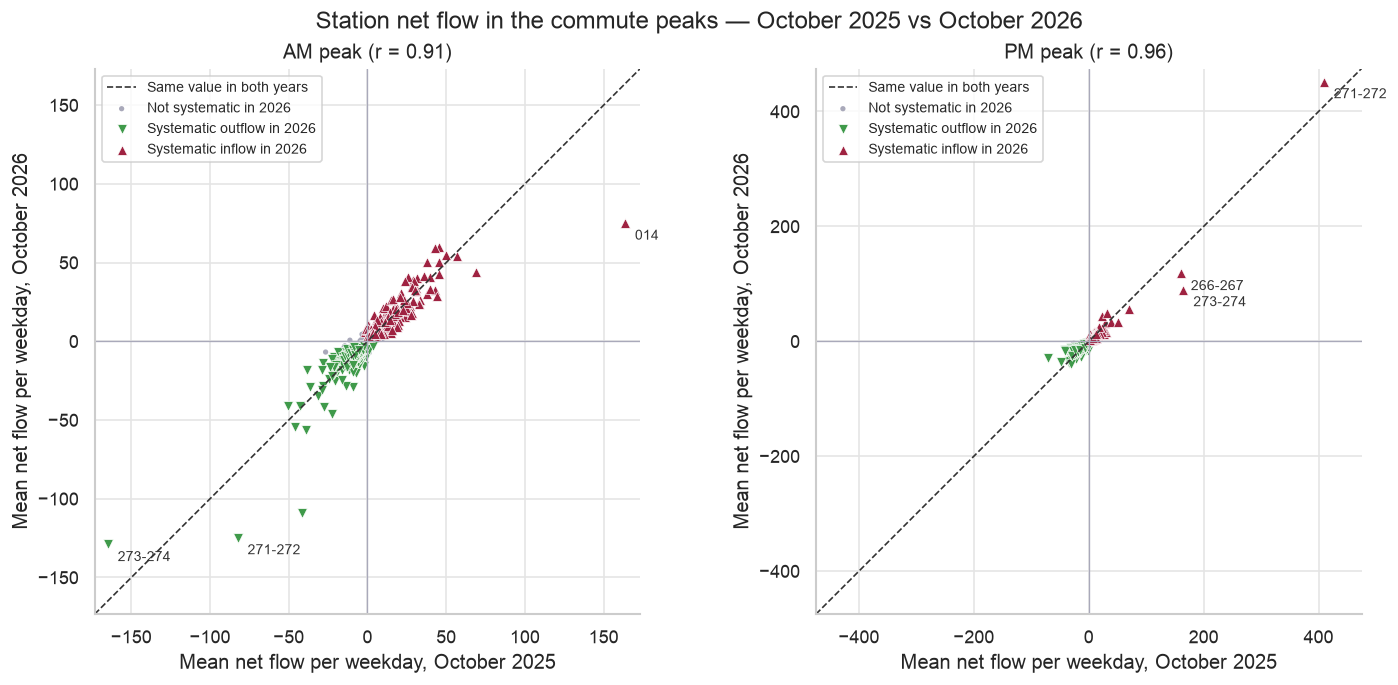

In [21]:
# Each point is a station: points near the diagonal kept the same net flow in both years.
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), layout="constrained")
for ax, slot in zip(axes, ["AM peak", "PM peak"]):
    pair = pd.concat({"2025": period_means["2025"].xs(slot, level="slot"),
                      "2026": mean_net_2026.xs(slot, level="slot")}, axis=1).dropna()
    flags = net_stats_2026["imbalance"].xs(slot, level="slot").reindex(pair.index)
    limit = np.abs(pair.to_numpy()).max() * 1.05
    ax.plot([-limit, limit], [-limit, limit], color=INK, lw=1, ls="--", label="Same value in both years")
    ax.axhline(0, color=CONTEXT, lw=0.8)
    ax.axvline(0, color=CONTEXT, lw=0.8)
    other = ~flags.isin(list(DIRECTION_STYLE))
    ax.scatter(pair.loc[other, "2025"], pair.loc[other, "2026"], s=10, color=CONTEXT, edgecolor="none",
               label="Not systematic in 2026")
    for flag, style in DIRECTION_STYLE.items():
        mask = flags.eq(flag)
        ax.scatter(pair.loc[mask, "2025"], pair.loc[mask, "2026"], edgecolor="white", linewidth=0.4,
                   **{**style, "label": f"{style['label']} in 2026"})
    # Name the three stations farthest from zero so the extreme points can be traced.
    for code in pair.abs().max(axis=1).nlargest(3).index:
        ax.annotate(code, pair.loc[code], textcoords="offset points", xytext=(6, -10), fontsize=8.5, color=INK)
    ax.set(title=f"{slot} (r = {pair['2025'].corr(pair['2026']):.2f})", xlim=(-limit, limit), ylim=(-limit, limit),
           xlabel="Mean net flow per weekday, October 2025", ylabel="Mean net flow per weekday, October 2026")
    ax.set_aspect("equal")
    ax.grid(True, color="#E5E5E5")
    ax.legend(loc="upper left", fontsize=8.5)
fig.suptitle("Station net flow in the commute peaks — October 2025 vs October 2026")
plt.show()

### Stability findings

- **Within October 2026** the station mean net flows of the two halves are highly correlated: from 0.87 (Midday) to 0.99 (PM peak). Between 79% and 93% of stations keep the same sign. Every 2026 systematic station-slot keeps its direction in both halves. This is expected, because the criterion already requires the same sign on 80% of days, but it confirms that the flags do not come from one part of the month despite the growing number of outages.
- **Between October 2025 and October 2026** the correlations remain high in the peaks: 0.91 in the AM peak and 0.96 in the PM peak. They are lower over the whole day (0.89) and at Midday (0.77). Of the 2026 systematic station-slots, between 97% and 100% have a 2025 mean of the same sign in each slot, except the whole day (89%).
- Meeting the full criterion again in 2025 is stricter. 82.5% of the PM-peak flags and 81.5% of the AM-peak flags repeat in the same direction, against 74% for Early and 60–68% for Midday, Evening and the whole day.
- By station type, 89 of the 135 morning-source/evening-sink stations and 86 of the 133 morning-sink/evening-source stations have exactly the same key flags in 2025. Whole-day net sinks are the least stable (23 of 46).
- **Conclusion:** the commute-peak imbalances are the most stable feature of the data and are a sound basis for planning. Whole-day imbalances change more between years and should be checked for the selected stations before they are used in a model.
- **The direction is more stable than the magnitude.** The labelled points in the scatter plots show this:
  - `271-272` has the largest PM-peak inflow in both years (about +410 in 2025 and +450 in 2026);
  - `273-274` has the largest AM-peak outflow in both years (about −165 and −130);
  - `014` (Reforma – Río de Plata) keeps its AM-peak inflow but halves it, from about +165 to +75.
  
  A model for the selected stations should take its rates from October 2026, not from 2025.

## 6. Station summary for the subnetwork selection

One row per station with the quantities computed above. To describe a candidate subnetwork, filter this table to its station codes. The columns are:

- `in_service_days`: weekdays in service in October 2026 (of 22).
- `pickups_per_day`, `dropoffs_per_day`: mean daily events on in-service days.
- `median_daily_net`: median whole-day net flow (drop-offs − pickups).
- `median_swing`, `swing_to_capacity`: median intraday swing and its ratio to the published capacity.
- `am_peak`, `pm_peak`, `whole_day`: systematic flag in each slot (`outflow`, `inflow` or empty).
- `station_type`: typology of Section 4.3.
- `stable_halves`: every systematic AM/PM/whole-day flag keeps its direction in both halves of October 2026 (empty when the station has none).
- `same_flag_2025`: every such flag is also systematic, in the same direction, in October 2025.

Set `SAVE_TABLES = True` to write this table and `station_slot_stats` to `outputs/` as CSV files. They are generated files and are not tracked by git; anyone can rebuild them by running the notebook.

In [22]:
SAVE_TABLES = False
KEY_SLOTS = {"AM peak": "am_peak", "PM peak": "pm_peak", "Whole day": "whole_day"}
SHORT_FLAG = {"Systematic outflow": "outflow", "Systematic inflow": "inflow"}

flags = net_stats_2026["imbalance"].unstack("slot")[list(KEY_SLOTS)]
key_flagged = flags.isin(list(SHORT_FLAG))


def flags_hold(reference):
    """True when every key systematic flag of 2026 keeps its direction in the reference means."""
    reference = reference.unstack("slot").reindex(index=flags.index, columns=list(KEY_SLOTS))
    expected = direction_2026.unstack("slot")[list(KEY_SLOTS)]
    holds = np.sign(reference).eq(expected) | ~key_flagged
    return holds.all(axis=1).where(key_flagged.any(axis=1))


halves_hold = (
    flags_hold(period_means["2026 first half"]) & flags_hold(period_means["2026 second half"])
).where(key_flagged.any(axis=1))
flags_2025 = net_stats_2025["imbalance"].unstack("slot").reindex(index=flags.index, columns=list(KEY_SLOTS))
same_2025 = (flags_2025.eq(flags) | ~key_flagged).all(axis=1).where(key_flagged.any(axis=1))

whole_day_means = slots_2026.loc[slots_2026["slot"].eq("Whole day")].groupby("station")[EVENTS].mean()
station_summary = (
    station_catalog.set_index("short_name")[["name", "lat", "lon", "capacity"]]
    .join(station_coverage["In service days"].rename("in_service_days"), how="inner")
    .join(whole_day_means.rename(columns={"pickup": "pickups_per_day", "dropoff": "dropoffs_per_day"}))
    .join(whole_day_net["median_net"].rename("median_daily_net"))
    .join(intraday_2026[["median_swing", "swing_to_capacity"]])
    .join(flags.replace(SHORT_FLAG).where(key_flagged, "").rename(columns=KEY_SLOTS))
    .join(station_type_2026)
    .join(halves_hold.map({True: "yes", False: "no"}).rename("stable_halves"))
    .join(same_2025.map({True: "yes", False: "no"}).rename("same_flag_2025"))
    .rename_axis("station")
)
station_summary[["stable_halves", "same_flag_2025"]] = station_summary[["stable_halves", "same_flag_2025"]].fillna("")

if SAVE_TABLES:
    Path("outputs").mkdir(exist_ok=True)
    station_summary.to_csv("outputs/station_imbalance_summary_2026.csv")
    station_slot_stats.to_csv("outputs/station_slot_stats_2026.csv")
    print("Saved: outputs/station_imbalance_summary_2026.csv, outputs/station_slot_stats_2026.csv")

print(f"{len(station_summary)} stations. Largest swing relative to capacity:")
station_summary.sort_values("swing_to_capacity", ascending=False).head(15).round(2)

676 stations. Largest swing relative to capacity:


,name,lat,lon,capacity,in_service_days,pickups_per_day,dropoffs_per_day,median_daily_net,median_swing,swing_to_capacity,am_peak,pm_peak,whole_day,station_type,stable_halves,same_flag_2025
station,,,,,,,,,,,,,,,,
271-272,CE-271-272 Jesús García - Carlos J. Meneses,19.44,-99.15,74,22,397.91,817.23,423.0,619.5,8.37,outflow,inflow,inflow,"Morning source, evening sink",yes,yes
208,CE-208 Hesiodo-Lamartine,19.43,-99.19,25,21,333.67,267.33,-70.0,103.0,4.12,outflow,,outflow,Net source (whole day),yes,yes
266-267,CE-266-267 Jesús García - Carlos J. Meneses,19.44,-99.15,74,22,231.86,287.59,75.5,216.5,2.93,outflow,inflow,,"Morning source, evening sink",yes,yes
014,CE-014 Reforma - Río de Plata,19.42,-99.17,39,22,236.18,282.50,48.0,102.5,2.63,inflow,outflow,inflow,"Morning sink, evening source",yes,yes
217,CE-217 Euler-Horacio,19.43,-99.18,31,22,153.27,199.55,42.0,80.0,2.58,inflow,outflow,inflow,"Morning sink, evening source",yes,yes
548,CE-548 Dr. Mariano Azuela - Jose Antonio Alzate,19.45,-99.15,39,22,330.45,363.23,33.5,99.0,2.54,outflow,inflow,,"Morning source, evening sink",yes,yes
242,CE-242 Pról. Moliere-Miguel de Cervantes Saavedra,19.44,-99.20,31,22,197.23,227.91,35.0,77.5,2.50,inflow,outflow,inflow,"Morning sink, evening source",yes,yes
273-274,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,19.44,-99.15,70,22,218.68,214.41,-7.0,170.5,2.44,outflow,inflow,,"Morning source, evening sink",yes,yes
017,CE-017 Reforma - Río Tiber,19.43,-99.17,27,21,180.19,189.76,8.0,64.0,2.37,inflow,outflow,,"Morning sink, evening source",yes,yes


In [23]:
# Do the stations with a key systematic flag keep it over time?
flagged_summary = station_summary.loc[station_summary["stable_halves"].ne("")]
pd.DataFrame({
    "Stations": flagged_summary.groupby("station_type").size(),
    "Stable in both 2026 halves": flagged_summary["stable_halves"].eq("yes").groupby(flagged_summary["station_type"]).sum(),
    "Same flags in 2025": flagged_summary["same_flag_2025"].eq("yes").groupby(flagged_summary["station_type"]).sum(),
}).reindex(STATION_TYPES).dropna(how="all").fillna(0).astype("int64")

,Stations,Stable in both 2026 halves,Same flags in 2025
station_type,,,
"Morning source, evening sink",135,135,89
"Morning sink, evening source",133,133,86
Net source (whole day),94,94,53
Net sink (whole day),46,46,23
One-peak imbalance,121,121,75


## 7. Summary, limitations and questions for Stage 2

### Summary

1. **Coverage:** 3.2% of station-days in October 2026 were not fully in service, against 0.2% in October 2025, and outages increased after October 7. Station statistics use in-service days only; no events were deleted.
2. **Time slots:** five slots follow the clean profile: Early 05–07, AM peak 07–10, Midday 10–16, PM peak 16–20 and Evening 20–00:30. Network totals of pickups and drop-offs are balanced in every slot; the imbalance is spatial.
3. **Descriptive statistics:** `station_slot_stats` gives, for every station, slot and event, the mean, median, p25–p75, standard deviation and dispersion index. Short slots are close to Poisson-like variability; long slots are overdispersed.
4. **Systematic imbalances:** with the criterion of at least 80% of days with the same sign and |median| at least 10% of capacity:
   - 67% of stations are imbalanced in the AM peak, 47% in the PM peak and 34% over the whole day;
   - 177 stations have a median intraday swing larger than their capacity;
   - 112 stations look balanced at the end of the day but not within it.
5. **Stability:** peak imbalances keep their direction between halves of the month and more than 80% of the flagged peak station-slots are flagged again, in the same direction, in October 2025. Whole-day imbalances are less stable.
6. **For the subnetwork selection:** `station_summary` lists every station with its activity, swing, flags, type and stability. Good candidates are contiguous groups that:
   - mix morning sources and morning sinks, so part of the imbalance can be absorbed internally;
   - have stable flags (`stable_halves` and `same_flag_2025` equal to `yes`);
   - have full coverage (22 in-service days).

### Limitations

- **Completed trips only.** A station that is empty records no pickups, and one that is full records no drop-offs, while the user goes elsewhere. Observed counts are therefore censored: a station with a large outflow may have even more unmet demand, and a station with low counts may be one that fails often rather than one with low demand. The systematic flags describe recorded movements, not failures.
- **No rebalancing records.** The files do not include the operator's truck movements, so net flow from trips is not the change in station inventory. The swing measures how much a station would move without intervention.
- **Capacities** come from the November 19, 2026 catalog and may differ from October 2026 or 2025.
- **Coverage.** Out-of-service and partial-coverage station-days are inferred from the absence of events, not from an operator log. Partial outages within an in-service day remain in the data.
- **Thresholds.** The 25% coverage threshold and the 80% / 10% imbalance criterion are judgements; Section 4.1 shows how the counts change with them.

### Questions for Stage 2

- At which time resolution are pickups and drop-offs at a station close to a Poisson process with a time-varying rate? The dispersion indices of Section 3 suggest that daily slot totals vary more than a constant-rate Poisson count.
- For the selected subnetwork, can the inventory of each station be modelled as a birth–death process (arrivals = drop-offs, departures = pickups) with capacity as a finite bound, and what share of time does it spend empty or full?
- How should the censoring of observed demand at empty and full stations be handled when estimating rates?